# 01 Finding waveguide modes

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Photonic-Architecture-Laboratories/elec438tools/blob/main/tutorials/01_mode_solver_basics.ipynb)

This tutorial introduces `elec438tools`, the course's Python mode solver. By the end you can set up a waveguide cross-section, find its modes, read their properties, plot their fields, check that a result has converged, and compute group index and dispersion.

Run the cells from top to bottom. Cells marked **Exercise** ask you to change something and explain what you see.

## How to use this notebook

**In Google Colab (recommended: nothing to install)**

1. Open the course copy: https://colab.research.google.com/github/Photonic-Architecture-Laboratories/elec438tools/blob/main/tutorials/01_mode_solver_basics.ipynb
   You can run and even edit this copy, but nothing you do is kept: Colab cannot save it back to GitHub, so your changes disappear when you close the tab.
2. To keep your work, make your own copy first: **File → Save a copy in Drive**. Colab opens the copy ("Copy of 01_mode_solver_basics.ipynb"), which is saved in your Google Drive under *Colab Notebooks*. Work in that copy from now on.
3. Run the cells in order with **Shift + Enter**, or all at once with **Runtime → Run all**. The first code cell installs `elec438tools` (about 20 s). Colab forgets installed packages when its runtime restarts, so that cell runs again in each new session.
4. Keep the default **CPU** runtime. The solver does not use a GPU, so a GPU runtime will not make it faster.

**On your own computer:** run `pip install git+https://github.com/Photonic-Architecture-Laboratories/elec438tools.git` once, then open the notebook in Jupyter or VS Code.

**Updates:** if the course copy changes during the semester, open the link again and save a new copy; your old copy keeps your own work.

In [1]:
# Setup: installs elec438tools if it is missing (on Colab this takes ~20 s)
import importlib.util, subprocess, sys
if importlib.util.find_spec("elec438tools") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "git+https://github.com/Photonic-Architecture-Laboratories/elec438tools.git"])

import numpy as np
import matplotlib.pyplot as plt
import elec438tools as et

## 1. What a mode solver computes

A waveguide that does not change along its length $z$ supports *modes*: field patterns that keep their shape as they propagate,

$$\mathbf{E}(x, y, z, t) = \mathbf{E}(x, y)\, e^{i(\beta z - \omega t)}, \qquad n_\mathrm{eff} = \frac{\beta}{k_0} = \frac{\beta \lambda}{2\pi}.$$

The solver takes the refractive index of the cross-section $n(x, y)$ and a wavelength, and returns the allowed pairs of $n_\mathrm{eff}$ and $\mathbf{E}(x, y), \mathbf{H}(x, y)$.

It uses the **finite-difference eigenmode (FDE)** method: the cross-section is divided into a rectangular (Yee) mesh, Maxwell's equations become a large sparse matrix, and its eigenvalues are $n_\mathrm{eff}^2$.

Conventions used everywhere in `elec438tools`:

* lengths and wavelengths in **micrometres** (1.55, not 1550);
* $x$ horizontal, $y$ vertical, $z$ the propagation direction;
* field arrays are indexed `[ix, iy]`.

## 2. A first waveguide

`strip_waveguide` builds the standard silicon strip: a Si core on SiO2 with SiO2 cladding. $x = 0$ is the centre of the core and $y = 0$ the top of the substrate. Printing the solver shows the region and the mesh.

ModeSolver(x_span=3.5 um, y_span=3.22 um, background=SiO2, 2 structures; mesh: Nx = 212  (dx 10.0-20.0 nm),  Ny = 184  (dy 10.0-20.0 nm),  78016 unknowns)


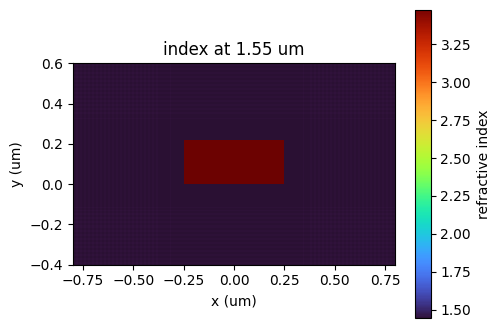

In [2]:
sim = et.strip_waveguide(width=0.5, height=0.22)
print(sim)
sim.plot_index(show_mesh=True, xlim=(-0.8, 0.8), ylim=(-0.4, 0.6));

Always look at the index profile before solving: it is the quickest way to catch a misplaced structure.

The solver region is surrounded by **metal walls** (perfect electric conductors). The fields of a guided mode must have decayed before they reach the walls, otherwise the walls change the answer; section 6 shows how to check this.

The mesh is finer (10 nm) in a box around the core and coarser (20 nm) elsewhere: a *mesh override region*. Mesh lines always land on material interfaces.

## 3. Building a cross-section yourself

The builder above is a shortcut. Here is the same waveguide set up by hand, which is how you would build any other geometry. Structures are painted in the order they are added: a later one overrides an earlier one where they overlap.

In [3]:
sim = et.ModeSolver(x_span=3.5, y_span=3.2, y_center=0.11, dx=0.02, background="SiO2")
sim.add(et.Layer(-np.inf, 0.0, "SiO2", name="substrate"))          # everything below y = 0
core = sim.add(et.Rect(width=0.5, height=0.22, x=0, y=0.11, material="Si", name="core"))
sim.add_mesh_override(x_min=-0.35, x_max=0.35, y_min=-0.1, y_max=0.32, dx=0.01)
print(sim)

ModeSolver(x_span=3.5 um, y_span=3.2 um, background=SiO2, 2 structures; mesh: Nx = 212  (dx 10.0-20.0 nm),  Ny = 183  (dy 10.0-20.1 nm),  77592 unknowns)


Materials can be `"Si"`, `"SiO2"`, `"air"`, or any number (a constant refractive index, complex for loss). Si and SiO2 include their wavelength dependence (Sellmeier models), which matters for group index:

In [4]:
for wl in (1.31, 1.55):
    print(f"{wl} um:  n_Si = {et.Si.n(wl).real:.4f},  n_SiO2 = {et.SiO2.n(wl).real:.4f}")

1.31 um:  n_Si = 3.5039,  n_SiO2 = 1.4468
1.55 um:  n_Si = 3.4777,  n_SiO2 = 1.4440


## 4. Finding modes

`solve` returns the modes whose effective index is closest to `n_guess`; by default that is the highest index in the structure, so the fundamental mode comes first.

In [5]:
modes = sim.solve(wavelength=1.55, num_modes=4)
modes

wavelength 1.55 um; guided means Re(neff) > 1.4440 (highest index at the region edge)
  # name                    neff  loss(dB/cm)  TE frac  Aeff(um2)  guided
  0 TE0                 2.446747            0    98.4%       0.19     yes
  1 TM0                 1.773126            0     4.4%     0.3392     yes
  2 TE1                 1.494311            0    69.5%     0.8021     yes
  3 -                   1.413319            0    99.9%      6.429      no

Reading the table:

* **neff**: effective index. Modes are sorted from highest to lowest.
* **loss**: propagation loss from the imaginary part of $n_\mathrm{eff}$ (zero here: no absorbing materials).
* **TE frac**: $\int |E_x|^2 / \int (|E_x|^2 + |E_y|^2)$, the *TE polarization fraction*. Above 50 % the mode is called TE-like, below it TM-like.
* **Aeff**: effective area $(\int |E|^2)^2 / \int |E|^4$.
* **guided**: whether $n_\mathrm{eff}$ is above the highest index at the edge of the region (here SiO2, 1.444). A mode below it is not confined by the core; it is a mode of the metal box.

Guided modes are named in order within each polarization: TE0, TE1, ... and TM0, TM1, .... Each mode can be fetched by name:

In [6]:
te0 = modes["TE0"]
print(te0)
print("beta =", te0.beta, "rad/um")
print("fraction of power in the core (confinement factor):", round(te0.power_fraction(core), 3))

<Mode 0 TE0: neff=2.446747, TE fraction=98.4%>
beta = (9.918300392220793+0j) rad/um
fraction of power in the core (confinement factor): 0.783


**Exercise.** Is this 500 nm wide waveguide single-mode at 1.55 um? Which of its modes are guided, and how close is the weakest one to the cladding index?

## 5. Plotting the fields

`plot_fields` shows all six field components, normalised so that the largest $|E|$ is 1. The H field is in matching physical units, so it is about $n/377$ times smaller.

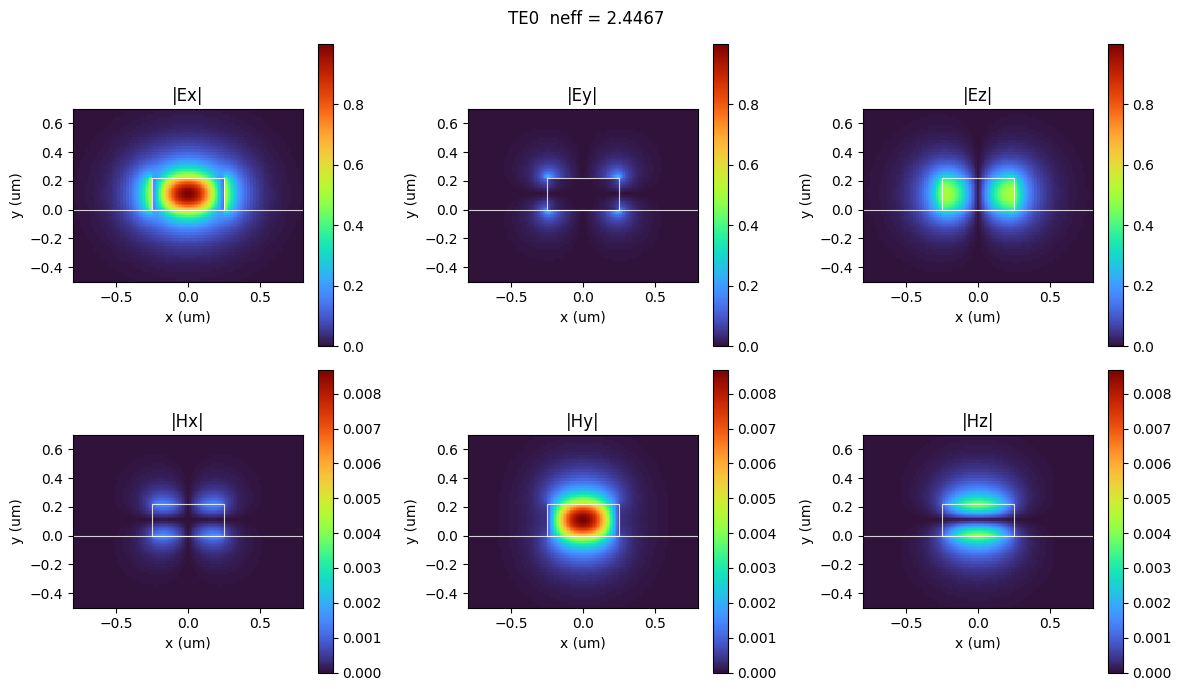

In [7]:
te0.plot_fields(xlim=(-0.8, 0.8), ylim=(-0.5, 0.7));

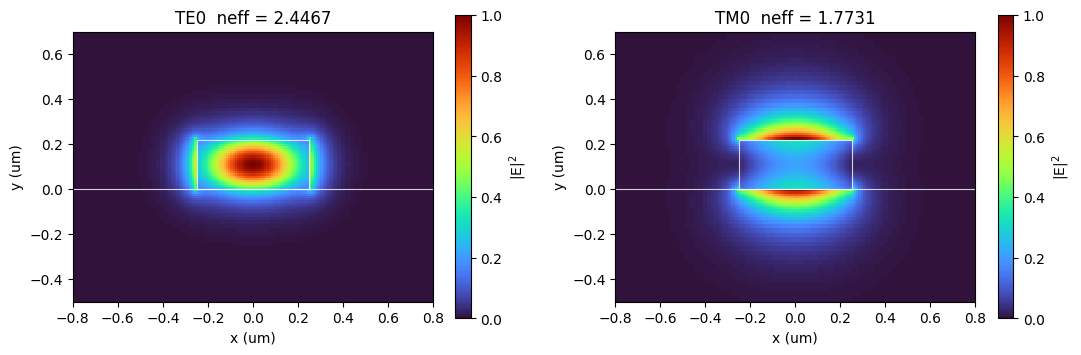

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
modes["TE0"].plot("E2", ax=axs[0], xlim=(-0.8, 0.8), ylim=(-0.5, 0.7))   # |E|^2, "E intensity"
modes["TM0"].plot("E2", ax=axs[1], xlim=(-0.8, 0.8), ylim=(-0.5, 0.7))
plt.tight_layout()

Any single component can be plotted as a magnitude, real part, imaginary part or phase: `"Ex"`, `"|Ex|"`, `"Re(Ex)"`, `"Im(Hy)"`, `"phase(Ex)"`; and the totals `"E"`, `"E2"`, `"H"`, `"Sz"` (power flow). Line cuts through the field maximum:

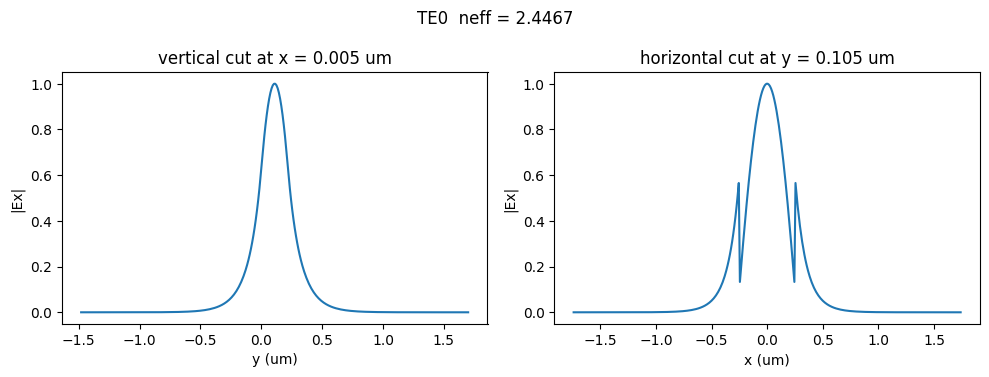

In [9]:
te0.plot_slice("Ex");

**Exercise.** In the horizontal cut, $|E_x|$ jumps at the sidewalls ($x = \pm 0.25$ um). Which boundary condition makes it jump, and by what factor? Check your answer against $n_\mathrm{Si}^2 / n_\mathrm{SiO_2}^2$. Then plot the vertical cut of $E_y$ for TM0 (`modes["TM0"].plot_slice("Ey")`) and explain where it jumps.

## 6. Convergence testing

A mode solver's answer depends on the mesh and on the size of the region. Before trusting a number, change each of them and check that the number stops changing. This is the most important habit in simulation.

**Mesh.** Refine the mesh and watch $n_\mathrm{eff}$ settle:

fine mesh   40 nm:  TE0 2.41750   TM0 1.77243


fine mesh   20 nm:  TE0 2.44563   TM0 1.77792


fine mesh   10 nm:  TE0 2.44674   TM0 1.77313


fine mesh    5 nm:  TE0 2.44703   TM0 1.77186


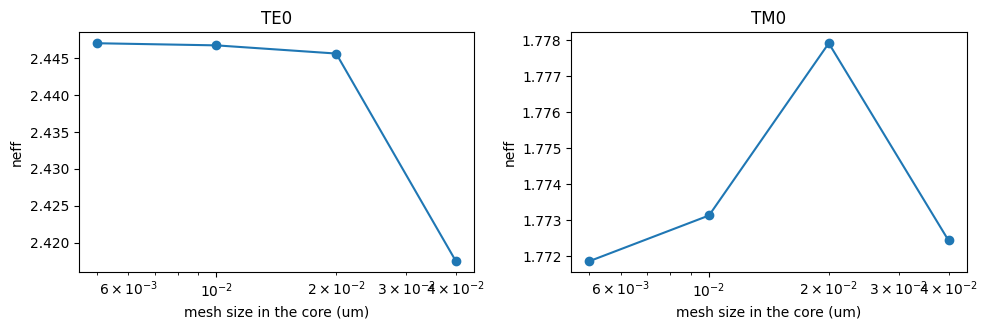

In [10]:
dxs = [0.04, 0.02, 0.01, 0.005]
neff_te, neff_tm = [], []
for dx in dxs:
    # default mesh 20 nm (or dx if coarser), refined to dx around the core
    m = et.strip_waveguide(0.5, 0.22, dx=max(dx, 0.02), fine_dx=dx).solve(1.55, num_modes=2)
    neff_te.append(m["TE0"].neff.real)
    neff_tm.append(m["TM0"].neff.real)
    print(f"fine mesh {dx*1e3:4.0f} nm:  TE0 {neff_te[-1]:.5f}   TM0 {neff_tm[-1]:.5f}")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].semilogx(dxs, neff_te, "o-"); axs[0].set_title("TE0")
axs[1].semilogx(dxs, neff_tm, "o-"); axs[1].set_title("TM0")
for a in axs:
    a.set_xlabel("mesh size in the core (um)"); a.set_ylabel("neff")
plt.tight_layout()

**Region size.** Move the metal walls closer and see when they start to matter. Weakly guided modes, whose fields spread far into the cladding, need the largest region. The solver warns when a guided mode has more than 1 % of its field next to a wall.

In [11]:
import warnings
margins = [0.3, 0.5, 0.8, 1.2, 1.5, 2.0]
for margin in margins:
    sim_m = et.strip_waveguide(0.5, 0.22, x_span=0.5 + 2 * margin, y_span=0.22 + 2 * margin)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        m = sim_m.solve(1.55, num_modes=3)
    names = "  ".join(f"{mode.name or '-'} {mode.neff.real:.4f}" for mode in m)
    print(f"walls {margin} um from the core:  {names}   ({len(w)} warnings)")

walls 0.3 um from the core:  TE0 2.4424  TM0 1.7944  TE1 1.5003   (2 warnings)


walls 0.5 um from the core:  TE0 2.4466  TM0 1.7771  TE1 1.5014   (2 warnings)


walls 0.8 um from the core:  TE0 2.4467  TM0 1.7734  TE1 1.4975   (1 warnings)


walls 1.2 um from the core:  TE0 2.4467  TM0 1.7731  TE1 1.4950   (1 warnings)


walls 1.5 um from the core:  TE0 2.4467  TM0 1.7731  TE1 1.4943   (0 warnings)


walls 2.0 um from the core:  TE0 2.4467  TM0 1.7731  TE1 1.4939   (0 warnings)


**Exercise.** How far away must the walls be for TE0's $n_\mathrm{eff}$ to be correct to 4 decimal places? Is the answer the same for the weakest guided mode? Explain why.

## 7. Wavelength dependence: group index and dispersion

The **group index** sets how fast a pulse travels and how far apart the resonances of a ring are:

$$n_g = n_\mathrm{eff} - \lambda \frac{dn_\mathrm{eff}}{d\lambda}.$$

`group_index=True` computes it for every mode (with two extra solves at nearby wavelengths, including the materials' own dispersion):

In [12]:
modes = et.strip_waveguide(0.5, 0.22).solve(1.55, num_modes=2, group_index=True)
modes

wavelength 1.55 um; guided means Re(neff) > 1.4440 (highest index at the region edge)
  # name                    neff  loss(dB/cm)  TE frac       ng  Aeff(um2)  guided
  0 TE0                 2.446741            0    98.4%   4.1945       0.19     yes
  1 TM0                 1.773128            0     4.4%   3.7573     0.3392     yes

To see the whole curve, sweep the wavelength. The modes are followed from one wavelength to the next by the overlap of their fields. The result also gives the dispersion parameter $D = -\frac{\lambda}{c}\frac{d^2 n_\mathrm{eff}}{d\lambda^2}$ in ps/(nm km).

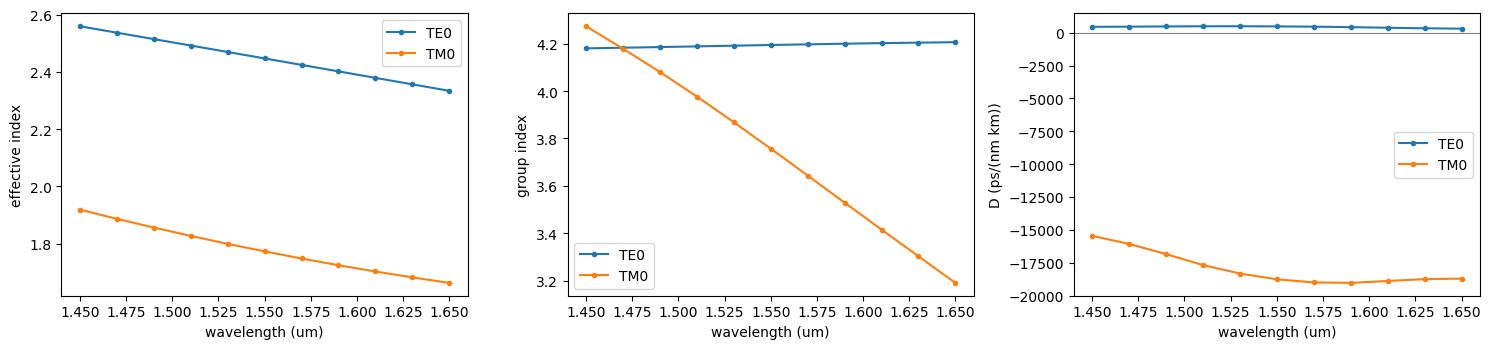

In [13]:
disp = et.strip_waveguide(0.5, 0.22).wavelength_sweep(np.linspace(1.45, 1.65, 11), num_modes=2)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
disp.plot("neff", ax=axs[0]); disp.plot("ng", ax=axs[1]); disp.plot("D", ax=axs[2])
plt.tight_layout()

**Exercise.** $n_\mathrm{eff}$ falls with wavelength but $n_g$ is much larger than $n_\mathrm{eff}$. Use the formula for $n_g$ to explain both facts.

## 8. Sweeping a dimension

`et.sweep` rebuilds and solves the waveguide for each value of a parameter. Here is the effective index of every guided mode against the core width. The dotted line is the cladding index: a mode is guided only above it, so the width where a curve meets the line is that mode's cutoff.

guided TE modes: [1 1 1 1 2 2 2 2 2 2 2 3 3 3 3 3]
guided TM modes: [1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2]


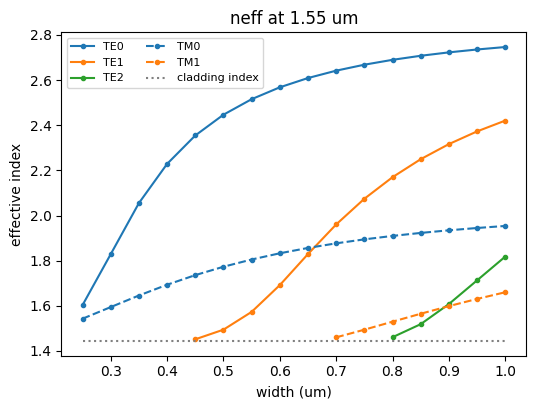

In [14]:
widths = np.arange(0.25, 1.01, 0.05)
res = et.sweep(lambda w: et.strip_waveguide(width=w, height=0.22), widths,
               wavelength=1.55, num_modes=6, param_name="width (um)")
res.plot()
print("guided TE modes:", res.num_guided("TE"))
print("guided TM modes:", res.num_guided("TM"))

`res.neff_te[:, 0]` is TE0 at every width, `res.neff_te[:, 1]` is TE1, and so on (NaN where the mode is not guided). `res.to_dataframe()` gives a table you can save to CSV.

**Exercise.** Read the single-mode width range for TE polarisation off the plot. Then repeat the sweep at 1.31 um and compare.

## 9. Other cross-sections

The same tools work for any geometry. A few that come up in this course:

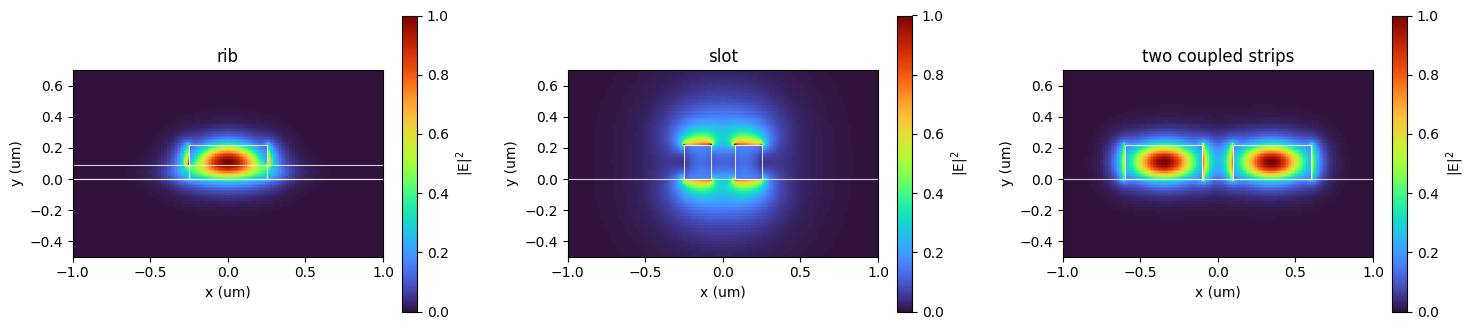

In [15]:
rib = et.rib_waveguide(width=0.5, height=0.22, slab_height=0.09)
slot = et.slot_waveguide(rail_width=0.175, gap=0.15, height=0.22)
pair = et.coupled_waveguides(width=0.5, gap=0.2, height=0.22)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.4))
for a, s, title in zip(axs, (rib, slot, pair), ("rib", "slot", "two coupled strips")):
    s.solve(1.55, num_modes=2)[0].plot("E2", ax=a, xlim=(-1.0, 1.0), ylim=(-0.5, 0.7))
    a.set_title(title)
plt.tight_layout()

Two coupled waveguides have an even and an odd **supermode**. Light launched into one guide moves fully to the other after the coupling length $L_c = \lambda / (2\,\Delta n_\mathrm{eff})$:

coupling length = 37.81 um


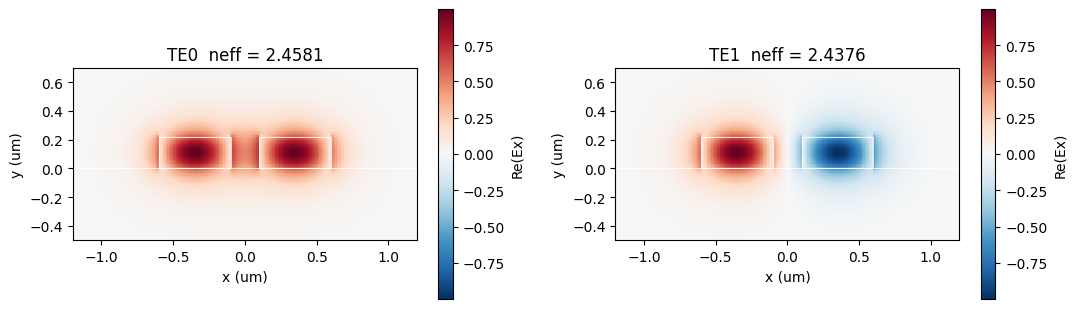

In [16]:
sm = pair.solve(1.55, num_modes=4)
even, odd = sm["TE0"], sm["TE1"]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
even.plot("Re(Ex)", ax=axs[0], xlim=(-1.2, 1.2), ylim=(-0.5, 0.7))
odd.plot("Re(Ex)", ax=axs[1], xlim=(-1.2, 1.2), ylim=(-0.5, 0.7))
plt.tight_layout()
print(f"coupling length = {1.55 / (2 * (even.neff.real - odd.neff.real)):.2f} um")

A **1D slab** is invariant in $x$; give `x_span=None` (or use `slab_waveguide`). Its modes are pure TE ($E_x, H_y, H_z$) or pure TM ($E_y, H_x, E_z$):

wavelength 1.55 um; guided means Re(neff) > 1.4440 (highest index at the region edge)
  # name                    neff  loss(dB/cm)  TE frac       ng  Aeff(um2)  guided
  0 TE0                 2.849333            0   100.0%   3.7064     0.2995     yes
  1 TM0                 2.055084            0     0.0%   3.9770     0.5139     yes


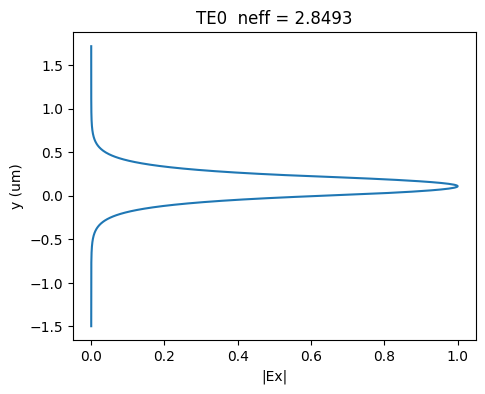

In [17]:
slab = et.slab_waveguide(thickness=0.22)
sm = slab.solve(1.55, num_modes=2, group_index=True)
print(sm)
sm["TE0"].plot("Ex");

A **bend** of radius $R$ can be modelled with `solve(..., bend_radius=R)`. The mode moves towards the outside of the bend. (Bend *loss* needs absorbing boundaries, which this version does not have yet, so only $n_\mathrm{eff}$ and the mode shape are meaningful.)

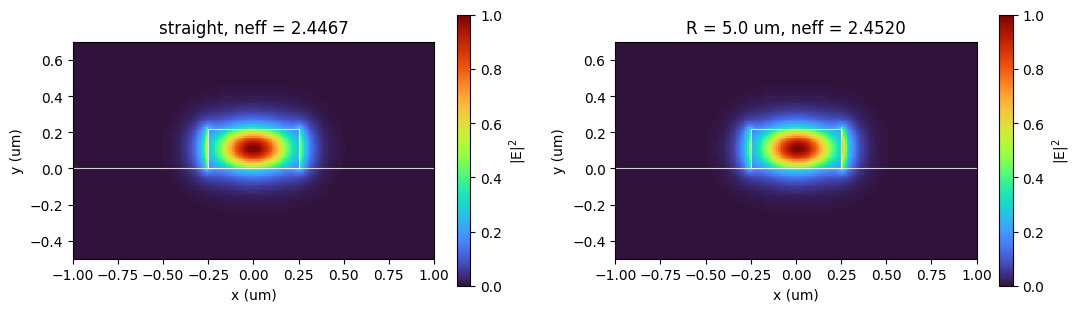

In [18]:
wide = et.strip_waveguide(0.5, 0.22, x_span=4.0)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
for a, R in zip(axs, (None, 5.0)):
    m = wide.solve(1.55, num_modes=1, bend_radius=R)[0]
    m.plot("E2", ax=a, xlim=(-1.0, 1.0), ylim=(-0.5, 0.7))
    a.set_title(f"R = {R} um, neff = {m.neff.real:.4f}" if R else f"straight, neff = {m.neff.real:.4f}")
plt.tight_layout()

## 10. Saving results, and working with an AI assistant

`mode.save("te0.mat")` writes the fields and properties to a `.mat` file, `mode.save("te0.npz")` to a NumPy file; `modes.to_dataframe()` and `res.to_dataframe()` give tables.

If you use an AI coding assistant, point it at `AGENTS.md` in the repository: it is a compact reference of everything in this package, written for exactly that purpose. Whatever the assistant writes, the checks in this tutorial still apply: look at the index profile, check convergence, and check that the walls are far enough away.

## Exercises

1. Find the TE0 and TM0 effective and group indices of a 220 nm thick slab and of the 500 x 220 nm strip at 1.55 um. Why is the strip's TE0 effective index lower than the slab's?
2. For a 220 nm thick Si strip in SiO2, plot $n_\mathrm{eff}$ of all guided modes against width from 0.2 to 1.5 um at 1.55 um. Mark the cutoff width of each mode.
3. Replace the SiO2 cladding with air (`cladding="air"`). Which modes change most, and why?
4. Repeat the convergence test of section 6 for the slot waveguide. Which mesh size do you need in the gap, and why is it smaller than for the strip?